# Self-Learning Lab Program 1 (Continuous Evaluation)
## Gradient Descent Variants, Optimizers, Regularization & Residual MLPs on Fashion-MNIST

**Framework:** PyTorch | **Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU* (CPU also works, just slower)

### Objectives
1. Demonstrate **batch**, **stochastic (SGD)** and **mini-batch** gradient descent on a small dataset.
2. Compare **momentum-based** (Momentum, Nesterov) and **adaptive** (Adagrad, RMSprop, Adam, AdamW) optimizers with **constant** and **scheduled** learning rates.
3. Investigate **overfitting** and evaluate **dropout, L2 regularization and data augmentation**.
4. Apply **early stopping**.
5. Compare **plain vs. residual MLPs** under controlled training conditions.

### Experimental design (controlled comparisons)
* Each experiment changes **one factor at a time**; seed, data subset, model, epochs and batch size are otherwise identical.
* Data is split into **train subset / validation / test**. The validation set is used for model selection and early stopping, and the **test set is only used for the final reported number**.

## 0. Setup & Imports

In [1]:
import time, copy, math, random
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Using device:', device, '| torch', torch.__version__)

Using device: cuda | torch 2.14.1+cu130


## 1. Data: A Subset of Fashion-MNIST
Fashion-MNIST has 60,000 training images (28×28 grayscale, 10 clothing classes). To keep every experiment fast, and to make overfitting easy to observe, we use only a **small subset**:

| Split | Size | Purpose |
|---|---|---|
| Train pool | 10,000 (experiments take the first *n* of these) | training |
| Validation | 2,000 | tuning, early stopping |
| Test | 2,000 | final evaluation only |

Images are normalised with the dataset mean/std and kept as `(N,1,28,28)` tensors on the device (so we can also apply image augmentation later).

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 198kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.4MB/s]


pool (10000, 1, 28, 28) | val (2000, 1, 28, 28) | test (2000, 1, 28, 28)


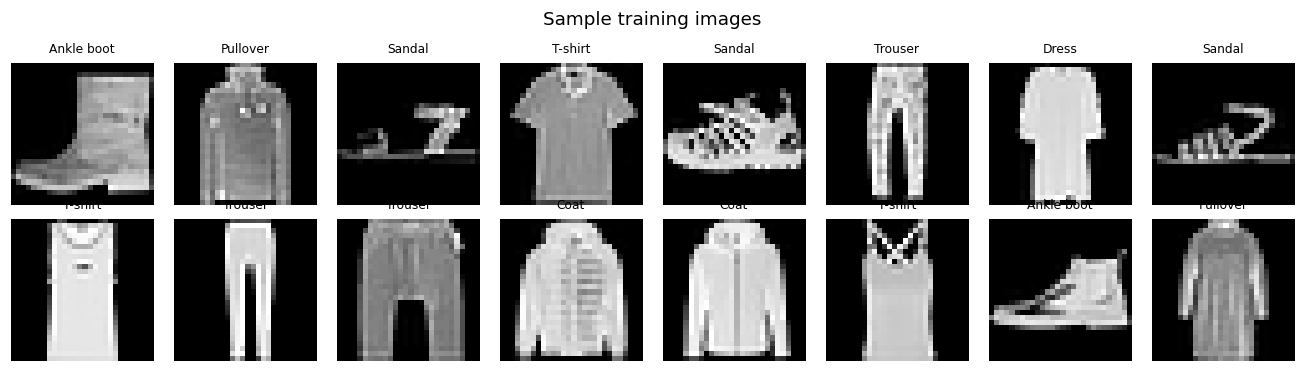

In [2]:
train_raw = datasets.FashionMNIST('./data', train=True,  download=True)
test_raw  = datasets.FashionMNIST('./data', train=False, download=True)
CLASSES = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
MEAN, STD = 0.2860, 0.3530

def prep(ds):
    x = ds.data.float().div(255.).unsqueeze(1)
    return (x - MEAN) / STD, ds.targets.clone()

X_all, y_all = prep(train_raw)
X_te_all, y_te_all = prep(test_raw)

g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(X_all), generator=g)
N_POOL, N_VAL, N_TEST = 10000, 2000, 2000
tr, va = perm[:N_POOL], perm[N_POOL:N_POOL + N_VAL]
te = torch.randperm(len(X_te_all), generator=g)[:N_TEST]

X_pool, y_pool = X_all[tr].to(device), y_all[tr].to(device)
X_val,  y_val  = X_all[va].to(device), y_all[va].to(device)
X_test, y_test = X_te_all[te].to(device), y_te_all[te].to(device)

def subset(n):
    # the first n samples of the (already shuffled) train pool
    return X_pool[:n], y_pool[:n]

print('pool', tuple(X_pool.shape), '| val', tuple(X_val.shape), '| test', tuple(X_test.shape))

def denorm(x): return (x * STD + MEAN).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(denorm(X_pool[i, 0]).cpu(), cmap='gray'); ax.set_title(CLASSES[y_pool[i]], fontsize=8); ax.axis('off')
plt.suptitle('Sample training images'); plt.tight_layout(); plt.show()

## 2. Reusable Building Blocks
This section defines the pieces used by every experiment: the **MLP**, an **evaluation function**, a **data-augmentation function**, an **early-stopping class**, a **manual mini-batch training loop** (so batch size is explicit and controllable) and plotting/summary helpers.

In [3]:
# ---------- Model ----------
def make_mlp(hidden=(256, 128), dropout=0.0, in_dim=784, n_classes=10):
    layers, d = [nn.Flatten()], in_dim
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]
        if dropout > 0: layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, n_classes))
    return nn.Sequential(*layers).to(device)

# ---------- Evaluation ----------
@torch.no_grad()
def evaluate(model, X, y, bs=2000):
    model.eval(); loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        loss += F.cross_entropy(out, y[i:i+bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i+bs]).sum().item()
    return loss / len(X), correct / len(X)

# ---------- Data augmentation (per-sample random flip + shift, on GPU) ----------
def augment_batch(x, max_shift=0.15):
    B = x.size(0)
    flip = (torch.rand(B, device=x.device) < 0.5).float() * 2 - 1          # +1 or -1 (horizontal flip)
    tx = (torch.rand(B, device=x.device) * 2 - 1) * max_shift              # shift in normalised coords (~2 px)
    ty = (torch.rand(B, device=x.device) * 2 - 1) * max_shift
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = flip; theta[:, 1, 1] = 1; theta[:, 0, 2] = tx; theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='border', align_corners=False)

# ---------- Early stopping ----------
class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.best_epoch, self.counter, self.best_state = float('inf'), 0, 0, None
    def step(self, val_loss, model, epoch):
        if val_loss < self.best - self.min_delta:
            self.best, self.best_epoch, self.counter = val_loss, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
        return self.counter >= self.patience          # True -> stop
    def restore(self, model):
        if self.best_state is not None: model.load_state_dict(self.best_state)

# ---------- Training loop ----------
def train(model, optimizer, X, y, epochs=20, bs=64, scheduler=None, sched_per_batch=False,
          augment=False, early_stopping=None, seed=0):
    keys = ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr', 'time']
    hist = {k: [] for k in keys}
    n, t0 = len(X), time.time()
    gen = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train()
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        order = torch.randperm(n, generator=gen).to(device)       # reshuffle every epoch
        for i in range(0, n, bs):                                  # bs=n -> batch GD, bs=1 -> SGD
            idx = order[i:i+bs]
            xb, yb = X[idx], y[idx]
            if augment: xb = augment_batch(xb)
            optimizer.zero_grad(set_to_none=True)
            F.cross_entropy(model(xb), yb).backward()
            optimizer.step()
            if scheduler is not None and sched_per_batch: scheduler.step()
        if scheduler is not None and not sched_per_batch: scheduler.step()
        # clean (no dropout / no augmentation) metrics at end of epoch
        tl, ta = evaluate(model, X, y); vl, va_ = evaluate(model, X_val, y_val)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va_]): hist[k].append(v)
        hist['time'].append(time.time() - t0)
        if early_stopping is not None and early_stopping.step(vl, model, ep): break
    if early_stopping is not None:
        early_stopping.restore(model); hist['best_epoch'] = early_stopping.best_epoch + 1
    else:
        hist['best_epoch'] = int(np.argmin(hist['val_loss'])) + 1
    return hist

def run(name, make_model, make_opt, X, y, epochs, bs, make_sched=None, sched_per_batch=False,
        augment=False, patience=None, seed=0):
    set_seed(seed)
    model = make_model(); opt = make_opt(model.parameters())
    sched = make_sched(opt) if make_sched else None
    es = EarlyStopping(patience) if patience else None
    h = train(model, opt, X, y, epochs, bs, sched, sched_per_batch, augment, es, seed)
    h['test_loss'], h['test_acc'] = evaluate(model, X_test, y_test)
    h['name'] = name; h['n_params'] = sum(p.numel() for p in model.parameters())
    return h

# ---------- Helpers: plots & tables ----------
def plot_runs(results, keys=('train_loss', 'val_loss', 'val_acc'), xlabel='Epoch', figsize=None, xkey=None):
    fig, axes = plt.subplots(1, len(keys), figsize=figsize or (5 * len(keys), 4)); axes = np.atleast_1d(axes)
    for ax, k in zip(axes, keys):
        for r in results:
            xs = r[xkey] if xkey else range(1, len(r[k]) + 1)
            ax.plot(xs, r[k], label=r['name'])
        ax.set_title(k.replace('_', ' ').title()); ax.set_xlabel(xlabel)
    axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

def summarize(results):
    rows = [{'Run': r['name'], 'Epochs run': len(r['val_acc']), 'Best epoch': r['best_epoch'],
             'Train acc': r['train_acc'][-1], 'Val acc': r['val_acc'][-1], 'Test acc': r['test_acc'],
             'Gap (train-val)': r['train_acc'][-1] - r['val_acc'][-1], 'Time (s)': r['time'][-1]} for r in results]
    return pd.DataFrame(rows).set_index('Run').round(4)
print('Helpers ready.')

Helpers ready.


## 3. Batch vs. Stochastic vs. Mini-Batch Gradient Descent
The three variants differ only in **how many samples are used to compute each gradient step**:

| Variant | Batch size | Updates per epoch | Gradient |
|---|---|---|---|
| **Batch GD** | N (all samples) | 1 | exact, smooth, slow per update |
| **Stochastic GD** | 1 | N | very noisy, many cheap updates |
| **Mini-batch GD** | B (e.g. 64) | N / B | compromise; exploits GPU parallelism |

**Setup:** a *small dataset* of 2,000 training images, a single-hidden-layer MLP (784→128→10), plain SGD optimizer (no momentum), identical learning rate (0.02), identical initialisation, 15 epochs.

In [4]:
N_SMALL, EPOCHS_GD, LR_GD = 2000, 15, 0.02
Xs, ys = subset(N_SMALL)
mk = partial(make_mlp, hidden=(128,))
mk_opt = lambda p: torch.optim.SGD(p, lr=LR_GD)

gd_runs = []
for name, bs in [('Batch GD (bs=2000)', N_SMALL), ('Mini-batch GD (bs=64)', 64), ('Stochastic GD (bs=1)', 1)]:
    print('Running', name, '...')
    r = run(name, mk, mk_opt, Xs, ys, EPOCHS_GD, bs)
    r['updates'] = [(e + 1) * math.ceil(N_SMALL / bs) for e in range(EPOCHS_GD)]
    gd_runs.append(r)

df = summarize(gd_runs)
df['Updates/epoch'] = [math.ceil(N_SMALL / b) for b in (N_SMALL, 64, 1)]
df.drop(columns=['Best epoch'])

Running Batch GD (bs=2000) ...
Running Mini-batch GD (bs=64) ...
Running Stochastic GD (bs=1) ...


,Epochs run,Train acc,Val acc,Test acc,Gap (train-val),Time (s),Updates/epoch
Run,,,,,,,
Batch GD (bs=2000),15,0.5465,0.5470,0.5630,-0.0005,0.4428,1
Mini-batch GD (bs=64),15,0.7660,0.7555,0.7480,0.0105,0.5889,32
Stochastic GD (bs=1),15,0.9040,0.8065,0.7885,0.0975,30.8018,2000


--- vs. epochs ---


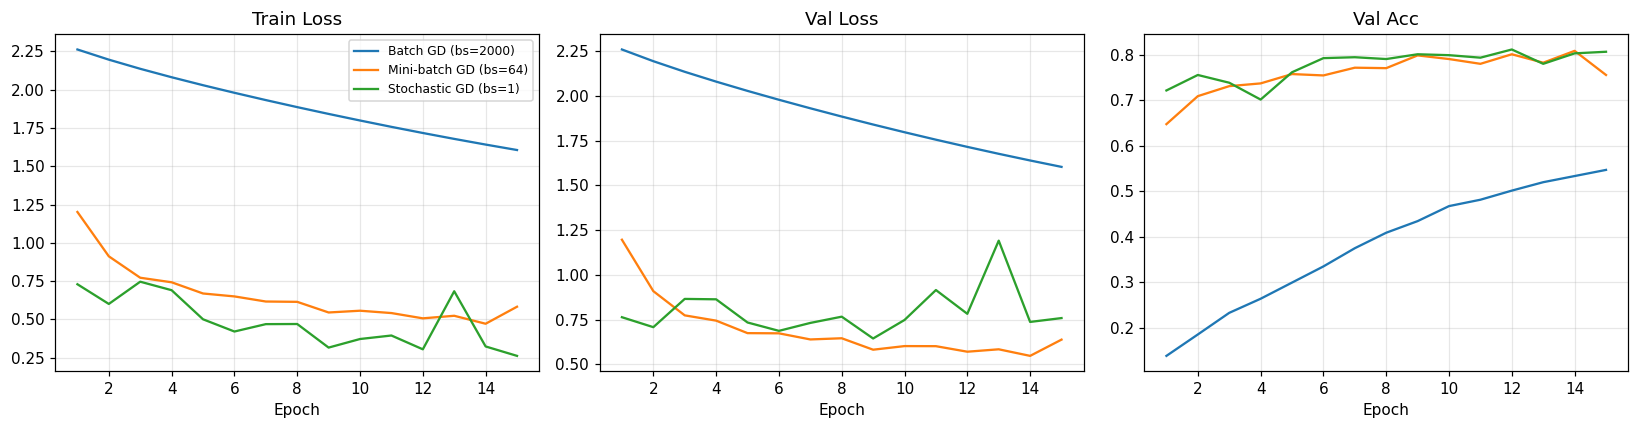

--- vs. number of parameter updates (log x) ---


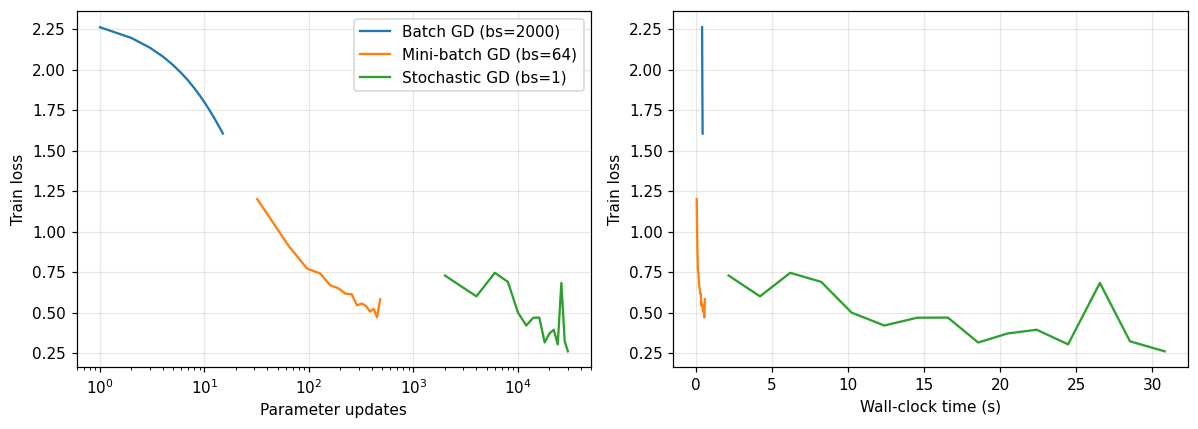

In [5]:
print('--- vs. epochs ---')
plot_runs(gd_runs, keys=('train_loss', 'val_loss', 'val_acc'), xlabel='Epoch')
print('--- vs. number of parameter updates (log x) ---')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for r in gd_runs:
    axes[0].plot(r['updates'], r['train_loss'], label=r['name']); axes[1].plot(r['time'], r['train_loss'], label=r['name'])
axes[0].set_xscale('log'); axes[0].set_xlabel('Parameter updates'); axes[1].set_xlabel('Wall-clock time (s)')
for a in axes: a.set_ylabel('Train loss')
axes[0].legend(); plt.tight_layout(); plt.show()

### Observations (Section 3)
*Fill in after running; use these prompts as a guide:*
* **Batch GD** makes only 15 updates in 15 epochs, so it is the slowest to reduce the loss per epoch even though each step uses the exact gradient.
* **SGD (bs=1)** makes the most updates per epoch and often reaches low loss in few epochs, but each epoch is **much slower in wall-clock time** (no parallelism) and its curve is noisier.
* **Mini-batch** typically offers the best trade-off between update frequency, gradient noise and run-time, which is why it is the default in practice.
* Note that with a *fixed* learning rate the comparison is not "fair" in every respect: larger batches usually tolerate (and benefit from) larger learning rates.

## 4. Momentum-Based and Adaptive Optimizers (Constant Learning Rate)
We now fix the batch size (128) and compare optimizers on a larger subset (10,000 images, MLP 784→256→128→10, 20 epochs).

| Optimizer | Idea |
|---|---|
| **SGD** | plain gradient step |
| **SGD + Momentum** | accumulates a velocity (exponential average of past gradients) to damp oscillations & accelerate along consistent directions |
| **Nesterov** | momentum with a *look-ahead* gradient evaluation |
| **Adagrad** | per-parameter step size divided by the root of the *accumulated* squared gradients (rates only shrink) |
| **RMSprop** | like Adagrad but with an *exponential moving average* of squared gradients |
| **Adam** | momentum (1st moment) + RMSprop (2nd moment) + bias correction |
| **AdamW** | Adam with *decoupled* weight decay |

Each optimizer uses a **typical default learning rate** (SGD-type ≈ 1e-2–5e-2, adaptive ≈ 1e-3), and the LR is **constant** in this section.

In [6]:
N_OPT, EPOCHS_OPT, BS_OPT = 10000, 20, 128
Xo, yo = subset(N_OPT)
mk = partial(make_mlp, hidden=(256, 128))

OPTIMIZERS = {
    'SGD (lr=0.05)':           lambda p: torch.optim.SGD(p, lr=0.05),
    'Momentum (lr=0.01)':      lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    'Nesterov (lr=0.01)':      lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True),
    'Adagrad (lr=0.01)':       lambda p: torch.optim.Adagrad(p, lr=0.01),
    'RMSprop (lr=1e-3)':       lambda p: torch.optim.RMSprop(p, lr=1e-3),
    'Adam (lr=1e-3)':          lambda p: torch.optim.Adam(p, lr=1e-3),
    'AdamW (lr=1e-3, wd=1e-2)':lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=1e-2),
}
opt_runs = [run(n, mk, f, Xo, yo, EPOCHS_OPT, BS_OPT) for n, f in OPTIMIZERS.items()]
summarize(opt_runs).drop(columns=['Epochs run']).sort_values('Val acc', ascending=False)

,Best epoch,Train acc,Val acc,Test acc,Gap (train-val),Time (s)
Run,,,,,,
Adam (lr=1e-3),10,0.9592,0.8680,0.8645,0.0912,2.5638
"AdamW (lr=1e-3, wd=1e-2)",10,0.9569,0.8670,0.8640,0.0899,2.5975
Momentum (lr=0.01),12,0.9319,0.8615,0.8515,0.0704,2.1676
Adagrad (lr=0.01),15,0.9274,0.8580,0.8600,0.0694,2.5616
Nesterov (lr=0.01),10,0.9174,0.8500,0.8430,0.0674,2.4089
SGD (lr=0.05),15,0.8516,0.8205,0.8175,0.0311,2.0062
RMSprop (lr=1e-3),9,0.8680,0.8025,0.8085,0.0655,2.3877


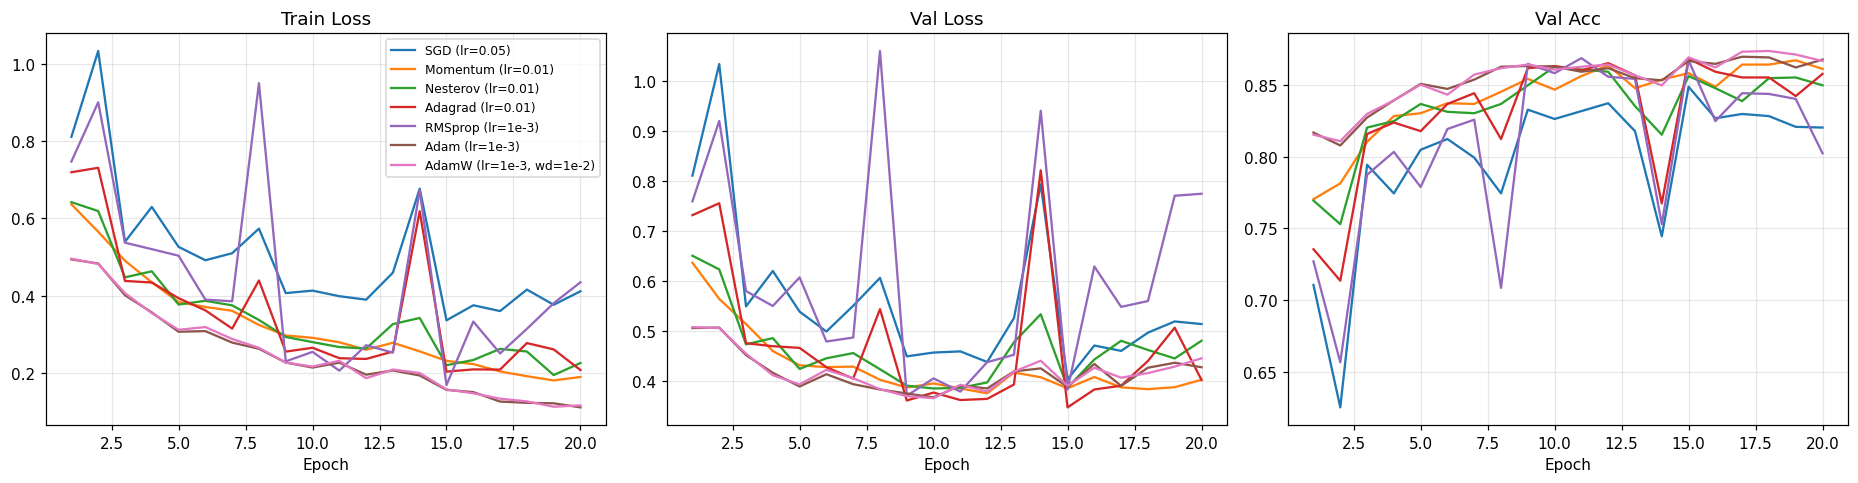

In [7]:
plot_runs(opt_runs, keys=('train_loss', 'val_loss', 'val_acc'), figsize=(17, 4.5))

### Observations (Section 4)
* Momentum/Nesterov usually converge **faster than plain SGD** at the same effective step size.
* Adaptive methods (Adam, RMSprop) are typically fast in early epochs with little tuning; **Adagrad** slows down as its accumulated denominator grows.
* Look at the **gap between train loss and val loss**: fast optimizers also overfit faster, which motivates Sections 6–8.

## 5. Learning-Rate Schedules
We compare a **constant LR** against four schedules for two representative optimizers, **SGD + Momentum** (base LR 0.01) and **Adam** (base LR 1e-3). Everything else is identical.

| Schedule | Rule |
|---|---|
| Constant | η(t) = η₀ |
| StepLR | halve η every 5 epochs |
| ExponentialLR | η(t) = η₀ · 0.85ᵗ |
| CosineAnnealing | smooth decay from η₀ to ≈0 over all epochs |
| OneCycle | warm-up to 3·η₀ then anneal (updated every batch) |


=== Momentum ===


,Best epoch,Train acc,Val acc,Test acc,Gap (train-val),Time (s)
Run,,,,,,
Momentum + Constant,12,0.9319,0.8615,0.8515,0.0704,2.4274
Momentum + StepLR,20,0.9068,0.8615,0.8575,0.0453,2.0935
Momentum + Exponential,18,0.8865,0.8490,0.8515,0.0375,2.1644
Momentum + Cosine,18,0.9142,0.8585,0.8585,0.0557,2.0496
Momentum + OneCycle,18,0.9613,0.8715,0.8715,0.0898,2.0572


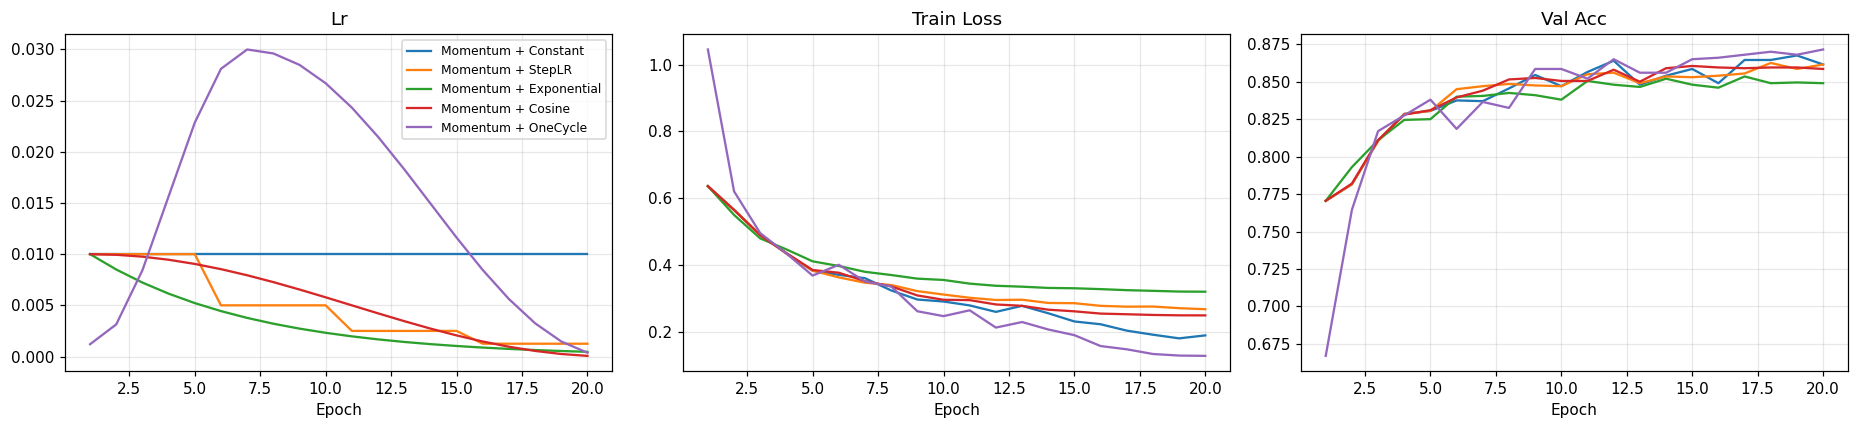


=== Adam ===


,Best epoch,Train acc,Val acc,Test acc,Gap (train-val),Time (s)
Run,,,,,,
Adam + Constant,10,0.9592,0.8680,0.8645,0.0912,2.5910
Adam + StepLR,20,0.9499,0.8720,0.8675,0.0779,2.6807
Adam + Exponential,18,0.9288,0.8665,0.8675,0.0623,2.4139
Adam + Cosine,18,0.9560,0.8750,0.8700,0.0810,2.8306
Adam + OneCycle,15,0.9735,0.8775,0.8750,0.0960,2.5461


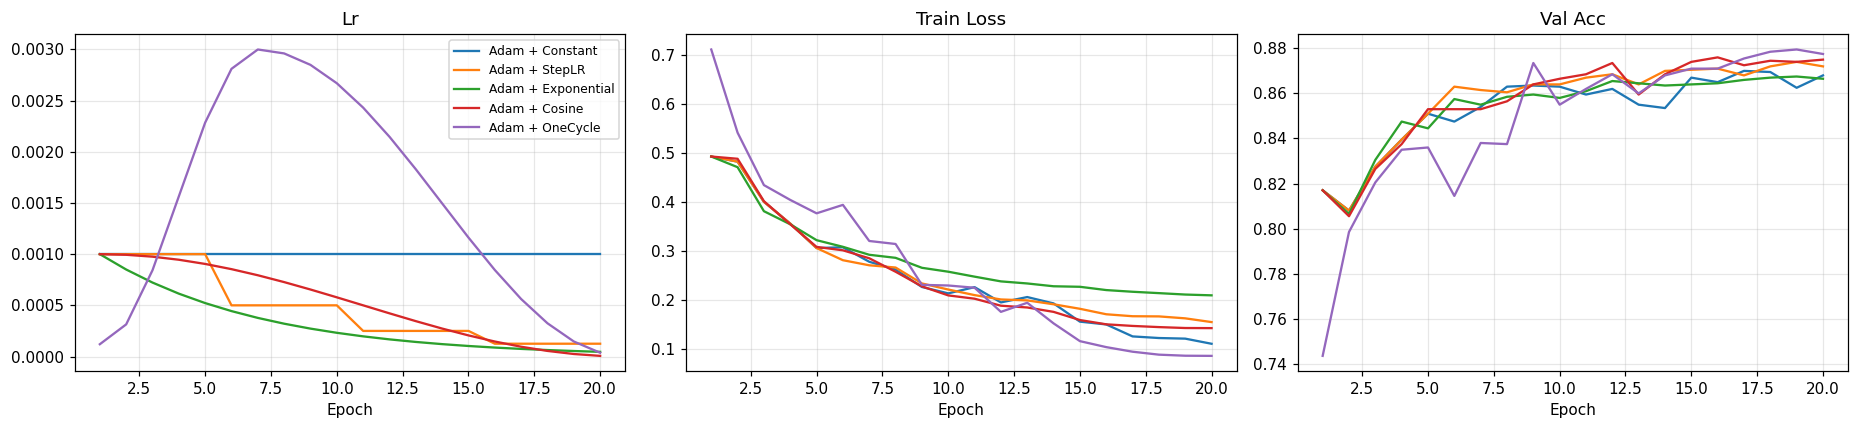

In [8]:
steps_per_epoch = math.ceil(N_OPT / BS_OPT)
def make_sched(name, base_lr):
    if name == 'Constant':    return None, False
    if name == 'StepLR':      return (lambda o: torch.optim.lr_scheduler.StepLR(o, step_size=5, gamma=0.5)), False
    if name == 'Exponential': return (lambda o: torch.optim.lr_scheduler.ExponentialLR(o, gamma=0.85)), False
    if name == 'Cosine':      return (lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=EPOCHS_OPT)), False
    if name == 'OneCycle':    return (lambda o: torch.optim.lr_scheduler.OneCycleLR(
                                  o, max_lr=3 * base_lr, total_steps=EPOCHS_OPT * steps_per_epoch)), True

BASES = {'Momentum': (lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9), 0.01),
         'Adam':     (lambda p: torch.optim.Adam(p, lr=1e-3), 1e-3)}
SCHEDS = ['Constant', 'StepLR', 'Exponential', 'Cosine', 'OneCycle']

sched_runs = {}
for bname, (mk_opt, base_lr) in BASES.items():
    sched_runs[bname] = []
    for s in SCHEDS:
        ms, per_batch = make_sched(s, base_lr)
        sched_runs[bname].append(run(f'{bname} + {s}', mk, mk_opt, Xo, yo, EPOCHS_OPT, BS_OPT, ms, per_batch))

for bname in BASES:
    print(f'\n=== {bname} ===')
    display(summarize(sched_runs[bname]).drop(columns=['Epochs run']))
    plot_runs(sched_runs[bname], keys=('lr', 'train_loss', 'val_acc'), figsize=(17, 4))

### Observations (Section 5)
* Decaying schedules (**Cosine, Step, Exponential**) typically give a smoother end of training and a slightly lower final loss than a constant rate, since large steps early help exploration and small steps late help settling.
* **OneCycle** (warm-up then annealing) often converges very quickly.
* Adam is less sensitive to schedule choice than SGD+Momentum, but scheduling still helps.
* Differences can be small on a small dataset and a single seed; report them cautiously.

## 6. Investigating Overfitting
Overfitting occurs when a model fits the *training* data increasingly well while **validation performance stagnates or degrades**. To provoke it we deliberately use:
* a **small** training set (2,000 images),
* a **high-capacity** MLP (784→512→512→10, ≈0.67 M parameters),
* **long training** (60 epochs) with Adam (lr = 1e-3).

Signs to look for: train accuracy → ~100 %, validation loss starts **rising** after some epoch while training loss keeps falling.

Params: 669,706 | best val-loss epoch: 4 | final train acc 0.978, val acc 0.829, test acc 0.835


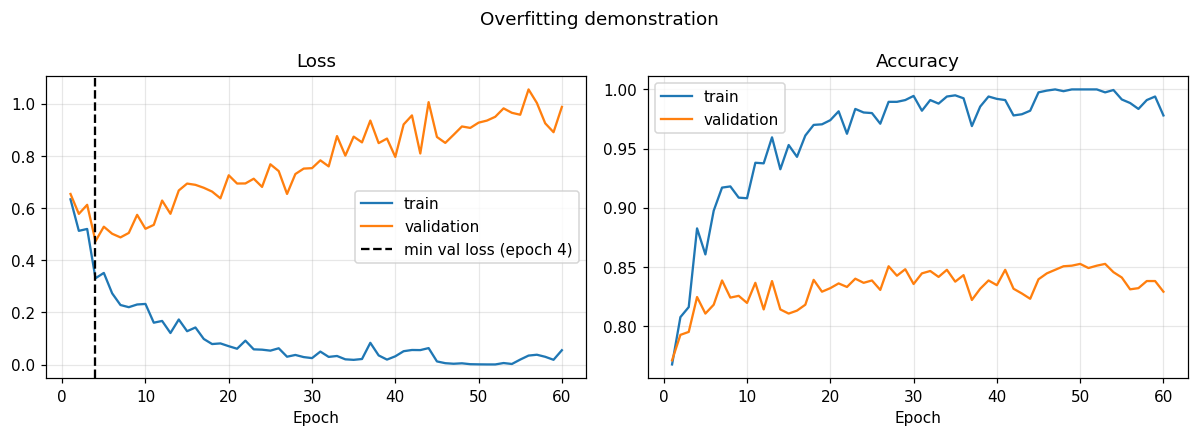

In [9]:
N_OF, EPOCHS_OF, BS_OF = 2000, 60, 64
Xf, yf = subset(N_OF)
mk_big   = partial(make_mlp, hidden=(512, 512))
adam     = lambda p: torch.optim.Adam(p, lr=1e-3)

base = run('Baseline (no regularization)', mk_big, adam, Xf, yf, EPOCHS_OF, BS_OF)
print(f"Params: {base['n_params']:,} | best val-loss epoch: {base['best_epoch']} | "
      f"final train acc {base['train_acc'][-1]:.3f}, val acc {base['val_acc'][-1]:.3f}, test acc {base['test_acc']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = range(1, EPOCHS_OF + 1)
ax[0].plot(ep, base['train_loss'], label='train'); ax[0].plot(ep, base['val_loss'], label='validation')
ax[0].axvline(base['best_epoch'], color='k', ls='--', label=f"min val loss (epoch {base['best_epoch']})")
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(ep, base['train_acc'], label='train'); ax[1].plot(ep, base['val_acc'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.suptitle('Overfitting demonstration'); plt.tight_layout(); plt.show()

**Reading the plot:** the region to the right of the dashed line is where the model keeps memorising the training set while generalisation stops improving, the classic **generalisation gap**.

## 7. Regularization: Dropout, L2 and Data Augmentation
Using exactly the same setup as Section 6, we add one regularizer at a time (then all together).

* **Dropout (p):** randomly zeroes hidden activations during training → prevents co-adaptation (acts like averaging many sub-networks). Disabled at evaluation.
* **L2 regularization / weight decay (λ):** adds λ‖w‖² to the loss (via `weight_decay` in Adam) → keeps weights small, smoother functions.
* **Data augmentation:** random horizontal flips and ±2-pixel shifts generated on the fly → effectively a larger training set that encodes invariances.

Below are examples of the augmentation used:

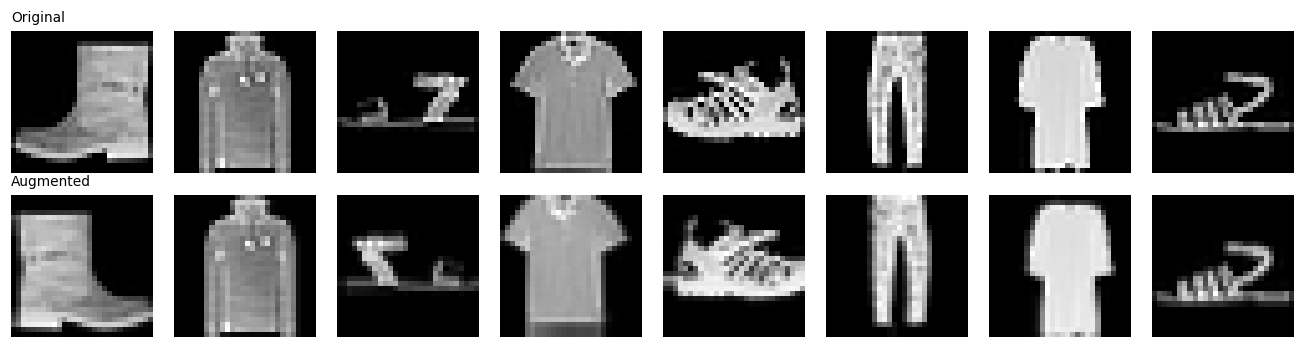

In [10]:
set_seed(1)
xb = Xf[:8]; xa = augment_batch(xb)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(denorm(xb[i, 0]).cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(denorm(xa[i, 0]).cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_title('Original', fontsize=9, loc='left'); axes[1, 0].set_title('Augmented', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

In [11]:
adam_l2 = lambda wd: (lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=wd))   # Adam's weight_decay = L2 penalty
reg_cfgs = [
    ('Baseline',                 dict(make_model=mk_big,                                  make_opt=adam,           augment=False)),
    ('Dropout p=0.2',            dict(make_model=partial(make_mlp, hidden=(512,512), dropout=0.2), make_opt=adam, augment=False)),
    ('Dropout p=0.5',            dict(make_model=partial(make_mlp, hidden=(512,512), dropout=0.5), make_opt=adam, augment=False)),
    ('L2 (1e-4)',                dict(make_model=mk_big,                                  make_opt=adam_l2(1e-4),  augment=False)),
    ('L2 (1e-3)',                dict(make_model=mk_big,                                  make_opt=adam_l2(1e-3),  augment=False)),
    ('Augmentation',             dict(make_model=mk_big,                                  make_opt=adam,           augment=True)),
    ('Dropout 0.3 + L2 1e-4 + Aug', dict(make_model=partial(make_mlp, hidden=(512,512), dropout=0.3), make_opt=adam_l2(1e-4), augment=True)),
]
reg_runs = [run(n, X=Xf, y=yf, epochs=EPOCHS_OF, bs=BS_OF, **cfg) for n, cfg in reg_cfgs]
reg_table = summarize(reg_runs)
reg_table

,Epochs run,Best epoch,Train acc,Val acc,Test acc,Gap (train-val),Time (s)
Run,,,,,,,
Baseline,60,4,0.978,0.8290,0.8350,0.1490,3.1966
Dropout p=0.2,60,8,0.998,0.8455,0.8395,0.1525,3.3363
Dropout p=0.5,60,9,0.979,0.8440,0.8350,0.1350,3.6221
L2 (1e-4),60,4,1.000,0.8425,0.8445,0.1575,3.2066
L2 (1e-3),60,4,0.999,0.8350,0.8265,0.1640,3.0676
Augmentation,60,35,0.931,0.8270,0.8290,0.1040,4.2792
Dropout 0.3 + L2 1e-4 + Aug,60,39,0.872,0.8115,0.8110,0.0605,5.0344


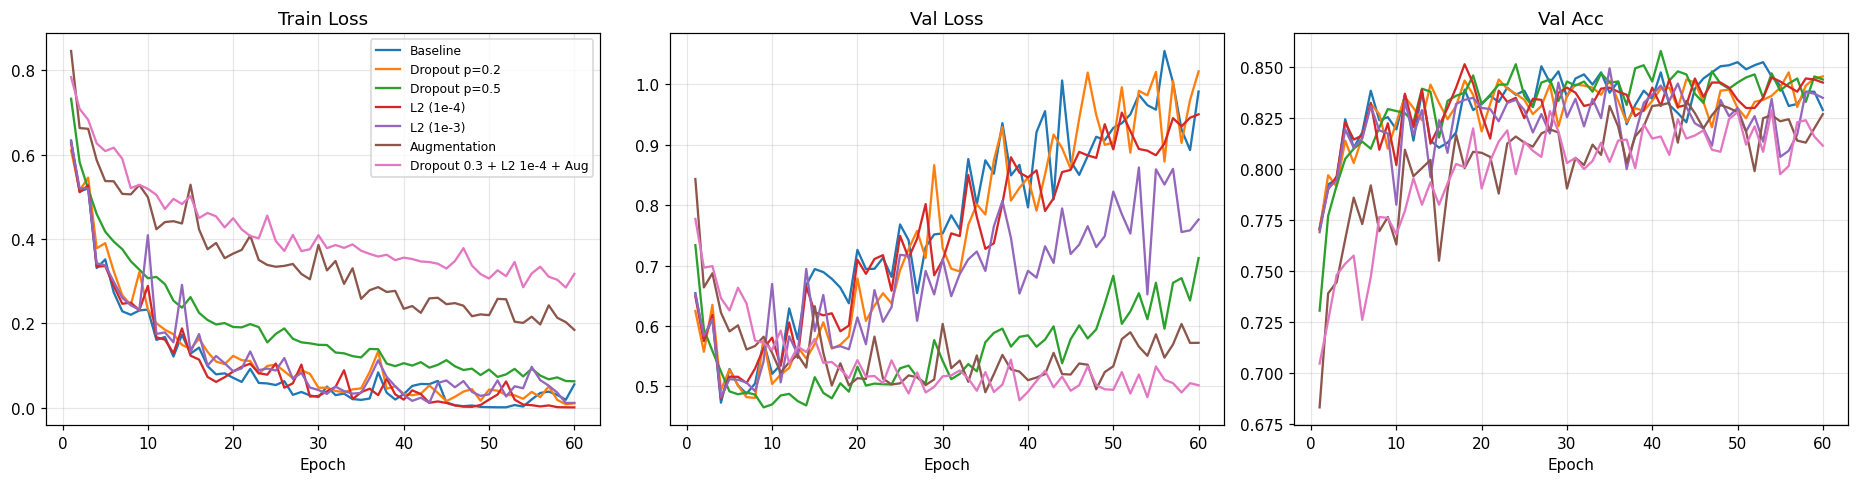

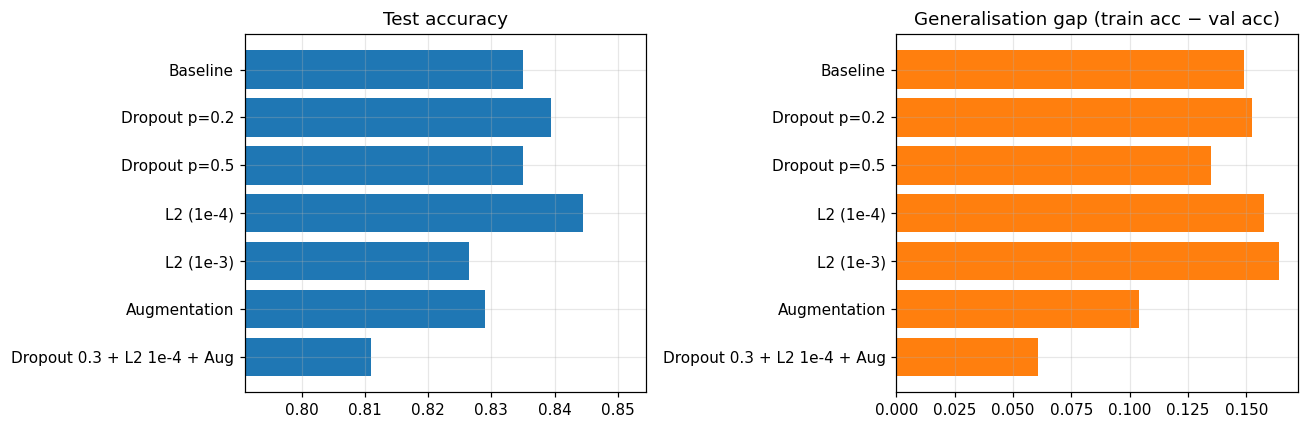

In [12]:
plot_runs(reg_runs, keys=('train_loss', 'val_loss', 'val_acc'), figsize=(17, 4.5))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
names = reg_table.index
ax[0].barh(names, reg_table['Test acc']); ax[0].set_xlim(reg_table['Test acc'].min() - 0.02, reg_table['Test acc'].max() + 0.01)
ax[0].set_title('Test accuracy'); ax[0].invert_yaxis()
ax[1].barh(names, reg_table['Gap (train-val)'], color='tab:orange'); ax[1].set_title('Generalisation gap (train acc − val acc)'); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

### Observations (Section 7)
* **Dropout** typically lowers the train–val gap and keeps validation loss from rising as quickly; a very high rate can underfit.
* **L2** shrinks weights and smooths the validation curve; too large a λ reduces accuracy.
* **Augmentation** is often the most effective single regularizer on image data, because it injects genuinely new (label-preserving) variation. The training loss measured on clean data will fall more slowly.
* Combining regularizers usually gives the best generalisation, but the best mix should be chosen on the **validation** set, not the test set.

## 8. Early Stopping
Early stopping monitors **validation loss** and halts training when it has not improved by at least `min_delta` for `patience` consecutive epochs; the **best weights are restored**. It acts as a regularizer by limiting the effective training time and also saves compute.

We allow up to 200 epochs with `patience = 7`, applied to (a) the baseline model and (b) the fully regularized model from Section 7.

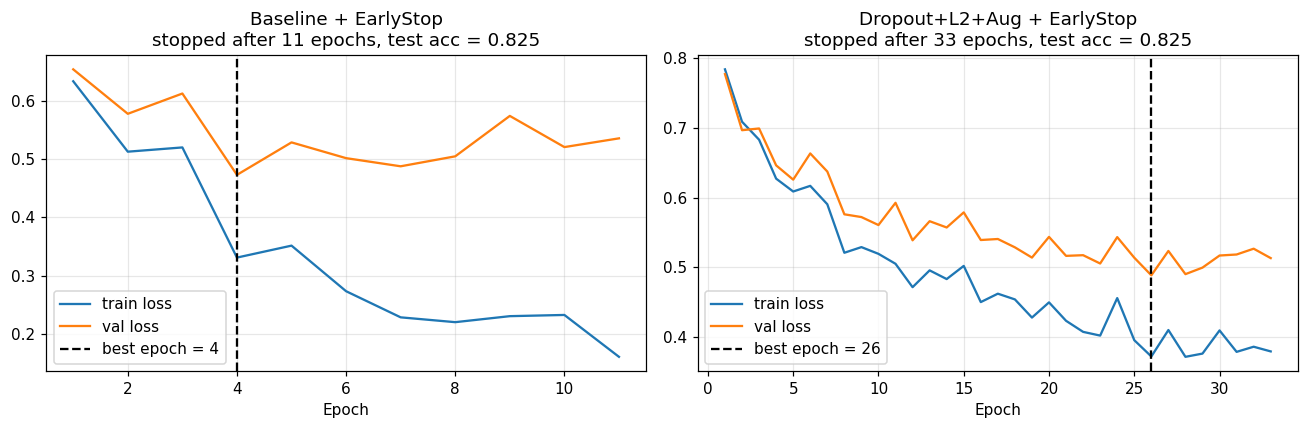

,Setting,Epochs run,Best epoch,Train acc,Val acc,Test acc,Time (s)
Run,,,,,,,
Baseline,fixed 60 epochs,60,4,0.9780,0.8290,0.8350,3.1966
Dropout 0.3 + L2 1e-4 + Aug,fixed 60 epochs,60,39,0.8720,0.8115,0.8110,5.0344
Baseline + EarlyStop,early stopping,11,4,0.9380,0.8365,0.8245,0.5586
Dropout+L2+Aug + EarlyStop,early stopping,33,26,0.8405,0.8040,0.8250,2.4594


In [13]:
cfg_base = dict(reg_cfgs)['Baseline']; cfg_all = dict(reg_cfgs)['Dropout 0.3 + L2 1e-4 + Aug']
es_base = run('Baseline + EarlyStop', X=Xf, y=yf, epochs=200, bs=BS_OF, patience=7, **cfg_base)
es_all  = run('Dropout+L2+Aug + EarlyStop', X=Xf, y=yf, epochs=200, bs=BS_OF, patience=7, **cfg_all)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, r in zip(axes, [es_base, es_all]):
    e = range(1, len(r['val_loss']) + 1)
    ax.plot(e, r['train_loss'], label='train loss'); ax.plot(e, r['val_loss'], label='val loss')
    ax.axvline(r['best_epoch'], color='k', ls='--', label=f"best epoch = {r['best_epoch']}")
    ax.set_title(f"{r['name']}\nstopped after {len(e)} epochs, test acc = {r['test_acc']:.3f}"); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.show()

cmp = pd.concat([reg_table.loc[['Baseline', 'Dropout 0.3 + L2 1e-4 + Aug']].assign(Setting='fixed 60 epochs'),
                 summarize([es_base, es_all]).assign(Setting='early stopping')])
cmp[['Setting', 'Epochs run', 'Best epoch', 'Train acc', 'Val acc', 'Test acc', 'Time (s)']]

### Observations (Section 8)
* Early stopping picks (approximately) the epoch with minimum validation loss, so the baseline's **test accuracy improves or at least matches** the fixed 60-epoch run while using fewer epochs.
* For an already well-regularized model, validation loss keeps improving longer, so early stopping triggers later and the gain is smaller.
* `patience` trades off between stopping too early (noisy validation curve) and wasting computation.

## 9. Plain MLP vs. Residual MLP (Controlled Comparison)
**Residual connections** (He et al., 2015) let a block learn a *correction* to its input, `y = x + F(x)`, which provides a direct gradient path and makes deep networks easier to optimise.

**Controls**
* Same width (128), same stem and classifier head, **same number of linear layers and exactly the same number of parameters**: a plain net with *L* hidden `Linear+ReLU` layers vs. a residual net with *L/2* blocks of `x + Linear(ReLU(Linear(x)))`.
* Same optimizer (SGD + Momentum, lr 0.01), batch size, epochs, data subset (5,000), PyTorch default initialisation, and **3 random seeds** per setting (identical seeds across both architectures).
* Depth is varied: L ∈ {2, 4, 8, 16, 24}. No BatchNorm/Dropout, so that only the skip connection differs.

In [14]:
class ResBlock(nn.Module):
    def __init__(self, w):
        super().__init__(); self.fc1, self.fc2 = nn.Linear(w, w), nn.Linear(w, w)
    def forward(self, x): return F.relu(x + self.fc2(F.relu(self.fc1(x))))

class DeepMLP(nn.Module):
    def __init__(self, depth=8, width=128, residual=False):
        super().__init__()
        stem = [nn.Flatten(), nn.Linear(784, width), nn.ReLU()]
        if residual: body = [ResBlock(width) for _ in range(depth // 2)]
        else:        body = [m for _ in range(depth) for m in (nn.Linear(width, width), nn.ReLU())]
        self.net = nn.Sequential(*stem, *body, nn.Linear(width, 10))
    def forward(self, x): return self.net(x)

# sanity check: identical parameter counts
for d in (8, 24):
    p = [sum(q.numel() for q in DeepMLP(d, residual=r).parameters()) for r in (False, True)]
    print(f'depth {d}: plain params = {p[0]:,} | residual params = {p[1]:,}')

# gradient reaching the FIRST layer at initialisation (vanishing-gradient diagnostic)
def first_layer_grad_norm(depth, residual, seed=0):
    set_seed(seed); m = DeepMLP(depth, residual=residual).to(device)
    xb, yb = Xo[:256], yo[:256]
    F.cross_entropy(m(xb), yb).backward()
    return m.net[1].weight.grad.norm().item()

DEPTHS = [2, 4, 8, 16, 24]
gn = pd.DataFrame({'depth': DEPTHS,
                   'plain':    [first_layer_grad_norm(d, False) for d in DEPTHS],
                   'residual': [first_layer_grad_norm(d, True)  for d in DEPTHS]}).set_index('depth')
print('\nGradient norm of first layer at initialisation:'); display(gn.round(5))

depth 8: plain params = 233,866 | residual params = 233,866
depth 24: plain params = 498,058 | residual params = 498,058

Gradient norm of first layer at initialisation:


,plain,residual
depth,,
2,0.28735,1.81838
4,0.04428,1.86527
8,0.00134,1.85367
16,0.00000,1.68857
24,0.00000,2.07797


In [15]:
N_RES, EPOCHS_RES, BS_RES, SEEDS = 5000, 20, 64, [0, 1, 2]
Xr, yr = subset(N_RES)
sgdm = lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)

res_rows, res_curves = [], {}
for d in DEPTHS:
    for residual in (False, True):
        kind = 'residual' if residual else 'plain'
        for s in SEEDS:
            r = run(f'{kind}-{d}', partial(lambda d, rs: DeepMLP(d, residual=rs).to(device), d, residual),
                    sgdm, Xr, yr, EPOCHS_RES, BS_RES, seed=s)
            res_rows.append(dict(depth=d, type=kind, seed=s, train_acc=r['train_acc'][-1],
                                 val_acc=r['val_acc'][-1], test_acc=r['test_acc'], time=r['time'][-1]))
            res_curves[(d, kind, s)] = r
    print(f'depth {d} done')

res_df = pd.DataFrame(res_rows)
agg = res_df.groupby(['depth', 'type'])[['train_acc', 'val_acc', 'test_acc']].agg(['mean', 'std']).round(4)
agg

depth 2 done
depth 4 done
depth 8 done
depth 16 done
depth 24 done


train_acc         val_acc         test_acc        
                    mean     std    mean     std     mean     std
depth type                                                       
2     plain       0.9411  0.0082  0.8417  0.0052   0.8457  0.0038
      residual    0.9480  0.0069  0.8463  0.0058   0.8417  0.0016
4     plain       0.9214  0.0073  0.8312  0.0012   0.8317  0.0033
      residual    0.9457  0.0048  0.8422  0.0048   0.8425  0.0048
8     plain       0.5973  0.1345  0.5853  0.1379   0.5958  0.1321
      residual    0.9613  0.0038  0.8498  0.0032   0.8447  0.0045
16    plain       0.1092  0.0000  0.0960  0.0000   0.0935  0.0000
      residual    0.9548  0.0026  0.8468  0.0065   0.8432  0.0029
24    plain       0.1092  0.0000  0.0960  0.0000   0.0935  0.0000
      residual    0.9537  0.0073  0.8432  0.0025   0.8423  0.0047

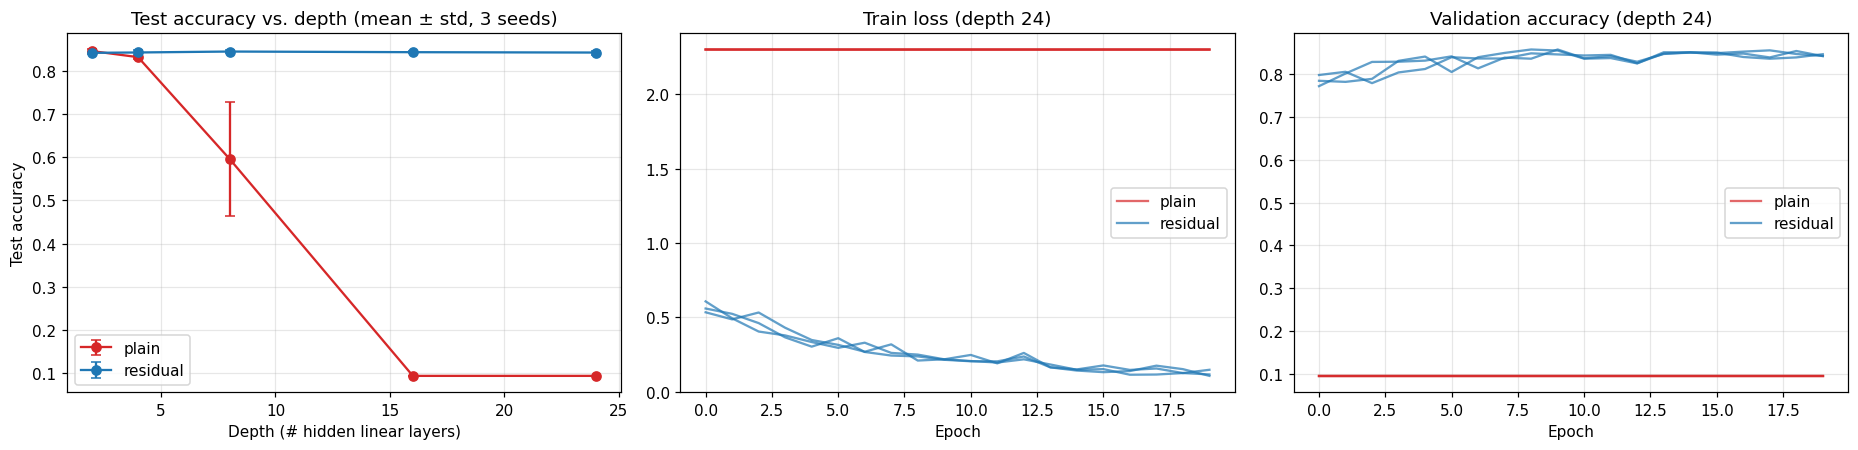

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for kind, c in [('plain', 'tab:red'), ('residual', 'tab:blue')]:
    g_ = res_df[res_df.type == kind].groupby('depth')['test_acc'].agg(['mean', 'std'])
    axes[0].errorbar(g_.index, g_['mean'], yerr=g_['std'], marker='o', capsize=3, label=kind, color=c)
axes[0].set_xlabel('Depth (# hidden linear layers)'); axes[0].set_ylabel('Test accuracy'); axes[0].set_title('Test accuracy vs. depth (mean ± std, 3 seeds)'); axes[0].legend()

for kind, c in [('plain', 'tab:red'), ('residual', 'tab:blue')]:
    for s in SEEDS:
        r = res_curves[(DEPTHS[-1], kind, s)]
        axes[1].plot(r['train_loss'], color=c, alpha=0.7, label=kind if s == 0 else None)
        axes[2].plot(r['val_acc'],   color=c, alpha=0.7, label=kind if s == 0 else None)
axes[1].set_title(f'Train loss (depth {DEPTHS[-1]})'); axes[2].set_title(f'Validation accuracy (depth {DEPTHS[-1]})')
for a in axes[1:]: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.show()

### Observations (Section 9)
* At **shallow depth** the two architectures perform similarly, because there is no real optimisation difficulty.
* As depth grows, the plain network's first-layer gradient (see the table above) shrinks and its training slows or stalls, whereas the residual network keeps a **direct identity path** for the gradient and continues to train, usually giving a higher accuracy at large depth with smaller variance across seeds.
* The two nets have **identical parameter counts**, so any difference comes from the architecture (optimisation ease), not capacity.
* Caveat: results use 3 seeds and a small subset; the exact crossover depth depends on initialisation, optimizer and learning rate.

## 10. Summary & Conclusions
Complete this section using your own numbers from the tables and plots above.

| Topic | Key finding (write your result) |
|---|---|
| Batch vs. SGD vs. mini-batch | e.g. mini-batch gives the best loss reduction per second; batch GD makes only 15 updates; SGD (bs=1) is slow per epoch and noisy |
| Momentum vs. adaptive optimizers | e.g. best optimizer = ___ with val acc ___ ; plain SGD slowest |
| Constant vs. scheduled LR | e.g. Cosine/OneCycle improved final val acc by ___ for Momentum and ___ for Adam |
| Overfitting | e.g. train acc reached ___ while val acc plateaued at ___; val loss minimum at epoch ___ |
| Dropout / L2 / Augmentation | e.g. best single regularizer = ___ ; combined test acc = ___ |
| Early stopping | e.g. stopped at epoch ___ ; test acc ___ vs ___ for fixed 60 epochs |
| Plain vs. residual | e.g. at depth 24: plain ___ % vs. residual ___ % |

### Take-aways
1. **Mini-batch gradient descent** is the practical default: frequent enough updates, moderate noise, hardware-efficient.
2. **Adaptive/momentum optimizers** converge faster than plain SGD and need less LR tuning; **schedules** refine the final solution.
3. **Overfitting** is driven by capacity vs. data size and training length; monitor the validation curve.
4. **Regularizers** (dropout, L2, augmentation) and **early stopping** each reduce the generalisation gap and can be combined.
5. **Residual connections** make deeper MLPs trainable under identical budgets.

### Limitations / possible extensions
* Single dataset subset and few seeds → differences of ≲1 % may not be statistically meaningful; add more seeds and confidence intervals.
* Learning rates were set to typical defaults, not tuned per optimizer; try a small LR sweep.
* Extensions: BatchNorm/LayerNorm, label smoothing, learning-rate warm-up, weight-decay sweeps, full 60 k training set.